# 03 Taylor Series

---

## 3.1 Why do we need Taylor Series?

In scientific computing, we rarely know the exact solution of a mathematical model.

Instead, we construct numerical methods that produce an approximation of the exact solution.

To understand how accurate these approximations are, we need a mathematical tool that describes how a function behaves near a given point.

Taylor series provides exactly this tool.

Instead of working with the original function, we replace it locally with a polynomial.

Since polynomials are much easier to differentiate, integrate and evaluate numerically, they become the foundation of many numerical methods.

Throughout this course, Taylor expansions will be used to

- derive finite-difference formulas,
- analyse discretisation errors,
- determine the order of numerical methods,
- derive Euler's method,
- study consistency.

Therefore, Taylor series is one of the most important mathematical tools in Simulation and Modelling.

---

### Learning Objectives

After this section you should be able to

- explain why Taylor series is needed,
- distinguish an exact function from its approximation,
- understand why numerical methods rely on local approximations.

## Question

Why do numerical methods prefer polynomial approximations instead of directly using complicated functions?

## Solution

Numerical methods repeatedly evaluate mathematical expressions.

Polynomials are easy to evaluate, differentiate and manipulate.

Therefore, replacing a complicated function with a polynomial makes numerical algorithms simpler and computationally efficient.

Taylor series provides a systematic way to construct such polynomial approximations.

## 3.2 Local Approximation

Taylor expansion is a **local approximation**.

This means that the approximation is usually most accurate near a selected point.

This selected point is called the **expansion point**.

We denote the expansion point by

$$
x_0.
$$

Suppose that we know a function at $x_0$ and want to estimate its value at a nearby point $x$.

We write the distance between these two points as

$$
h = x-x_0.
$$

Therefore,

$$
x=x_0+h.
$$

Taylor expansion uses information at $x_0$ to approximate the function at $x_0+h$.

The information used is

- the function value,
- the first derivative,
- the second derivative,
- and possibly higher derivatives.

The approximation becomes more detailed when more derivative terms are included.

### Important Notation

The expression

$$
f(x_0)
$$

is the value of the function at the expansion point.

The expression

$$
f'(x_0)
$$

is the slope of the function at the expansion point.

The expression

$$
f''(x_0)
$$

describes how the slope changes near the expansion point.

The expression

$$
h=x-x_0
$$

is the distance from the expansion point.

In numerical methods, $h$ often represents a small step size.

## Question 1

What does the word **local** mean in a Taylor approximation?

## Solution 1

A local approximation is designed to be accurate near one selected point.

Taylor expansion uses information at the expansion point $x_0$ to estimate the function at nearby points.

The approximation may become less accurate when $x$ moves far away from $x_0$.

## 3.3 Zeroth-Order Approximation

The simplest approximation uses only the function value at the expansion point.

$$
f(x_0+h)\approx f(x_0).
$$

This is called the **zeroth-order Taylor approximation**.

It assumes that the function is approximately constant near $x_0$.

This approximation ignores the slope and curvature of the function.

### Example

Consider

$$
f(x)=e^x
$$

and choose

$$
x_0=0.
$$

Since

$$
f(0)=e^0=1,
$$

the zeroth-order approximation is

$$
e^h\approx 1.
$$

This approximation is reasonable only when $h$ is small.

In [422]:
import numpy as np
import matplotlib.pyplot as plt

### Code Logic

We import two libraries.

`numpy` is used for numerical calculations.

```python
import numpy as np

In [423]:
x = np.linspace(-1.0, 1.0, 200)

exact = np.exp(x)
taylor_0 = np.ones_like(x)

### Code Logic

The command

```python
np.linspace(-1.0, 1.0, 200)

creates 200 equally spaced values between -1 and 1.

These values are stored in the variable x.

np.ones_like(x)

creates an array of ones with the same size and shape as x.

This represents the zeroth-order approximation

e^x\approx 1.


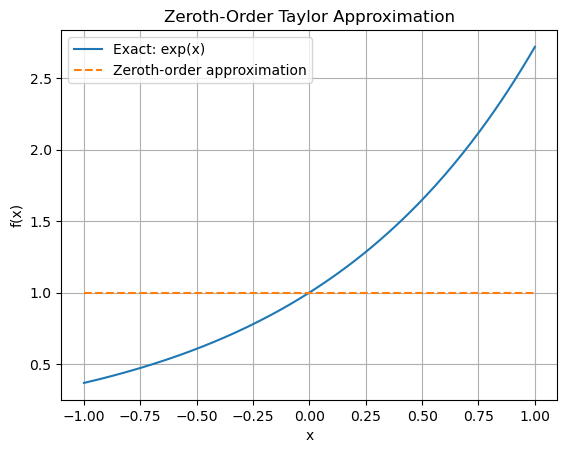

In [424]:
plt.plot(x, exact, label="Exact: exp(x)")
plt.plot(x, taylor_0, "--", label="Zeroth-order approximation")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Zeroth-Order Taylor Approximation")
plt.legend()
plt.grid()
plt.show()

### Interpretation

The exact function changes with $x$.

The zeroth-order approximation stays constant at

$$
1.
$$

The approximation is closest to the exact function near

$$
x_0=0.
$$

As the distance from $x_0$ increases, the difference between the exact function and the approximation increases.

## Question 2

For

$$
f(x)=\cos(x)
$$

with expansion point

$$
x_0=0,
$$

what is the zeroth-order approximation?

## Solution 2

The zeroth-order approximation is

$$
f(x_0+h)\approx f(x_0).
$$

Since

$$
\cos(0)=1,
$$

we obtain

$$
\cos(h)\approx 1.
$$

## 3.4 First-Order Taylor Approximation

The zeroth-order approximation ignores the slope of the function.

We can improve the approximation by including the first derivative.

The first-order Taylor approximation is

$$
f(x_0+h)
\approx
f(x_0)+h f'(x_0).
$$

Because

$$
h=x-x_0,
$$

the same expression can be written as

$$
f(x)
\approx
f(x_0)+(x-x_0)f'(x_0).
$$

This is the equation of the tangent line at $x_0$.

Therefore, the first-order Taylor approximation replaces the function locally with its tangent line.

### Meaning of the Terms

In

$$
f(x_0+h)
\approx
f(x_0)+h f'(x_0),
$$

the term

$$
f(x_0)
$$

gives the starting value.

The term

$$
h f'(x_0)
$$

estimates how much the function changes when we move a distance $h$.

The derivative $f'(x_0)$ is the rate of change.

Multiplying the rate of change by the step size gives an estimated change.

### Example: Exponential Function

Let

$$
f(x)=e^x
$$

and choose

$$
x_0=0.
$$

The function value is

$$
f(0)=1.
$$

The derivative is

$$
f'(x)=e^x.
$$

Therefore,

$$
f'(0)=1.
$$

The first-order approximation becomes

$$
e^h
\approx
1+h.
$$

If we use $x$ instead of $h$, because $x_0=0$, we obtain

$$
e^x\approx 1+x.
$$

In [425]:
taylor_1 = 1 + x

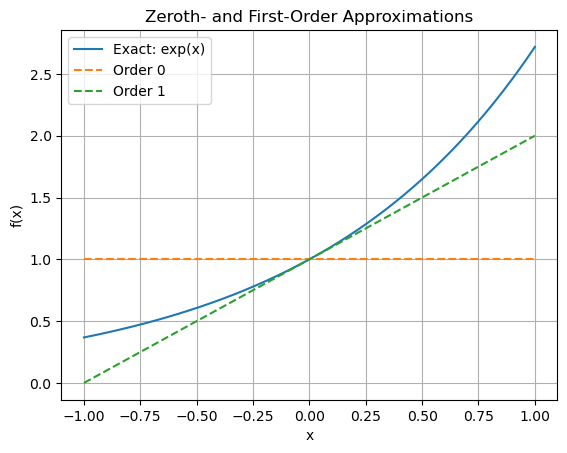

In [426]:
plt.plot(x, exact, label="Exact: exp(x)")
plt.plot(x, taylor_0, "--", label="Order 0")
plt.plot(x, taylor_1, "--", label="Order 1")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Zeroth- and First-Order Approximations")
plt.legend()
plt.grid()
plt.show()

### Interpretation

The first-order approximation follows the exact function better than the zeroth-order approximation near $x_0=0$.

This happens because the first-order approximation matches both

- the function value,
- and the first derivative

at the expansion point.

## Question 3

Find the first-order Taylor approximation of

$$
f(x)=\sin(x)
$$

around

$$
x_0=0.
$$

## Solution 3

The first-order Taylor formula is

$$
f(x_0+h)
\approx
f(x_0)+h f'(x_0).
$$

For

$$
f(x)=\sin(x),
$$

we have

$$
f(0)=\sin(0)=0.
$$

The first derivative is

$$
f'(x)=\cos(x).
$$

Therefore,

$$
f'(0)=\cos(0)=1.
$$

Substituting these values gives

$$
\sin(h)\approx 0+h(1).
$$

Thus,

$$
\sin(h)\approx h.
$$

Since $x_0=0$, this can also be written as

$$
\sin(x)\approx x.
$$

## 3.5 Second-Order Taylor Approximation

The first-order approximation includes the slope but ignores the curvature.

We improve the approximation by adding the second derivative term.

The second-order Taylor approximation is

$$
f(x_0+h)
\approx
f(x_0)
+
h f'(x_0)
+
\frac{h^2}{2}f''(x_0).
$$

The second derivative describes the local curvature of the function.

The factor

$$
\frac{1}{2}
$$

comes from

$$
2!=2.
$$

### Factorial

The factorial of a positive integer is the product of all positive integers up to that number.

For example,

$$
1!=1,
$$

$$
2!=2\cdot1=2,
$$

$$
3!=3\cdot2\cdot1=6,
$$

and

$$
4!=4\cdot3\cdot2\cdot1=24.
$$

By definition,

$$
0!=1.
$$

Factorials appear in the denominators of Taylor-series terms.

### Example: Exponential Function

For

$$
f(x)=e^x,
$$

all derivatives are equal to $e^x$.

At

$$
x_0=0,
$$

we have

$$
f(0)=1,
$$

$$
f'(0)=1,
$$

and

$$
f''(0)=1.
$$

Therefore, the second-order approximation is

$$
e^h
\approx
1+h+\frac{h^2}{2}.
$$

Since $x_0=0$, we can write

$$
e^x
\approx
1+x+\frac{x^2}{2}.
$$

In [427]:
taylor_2 = 1 + x + x**2 / 2

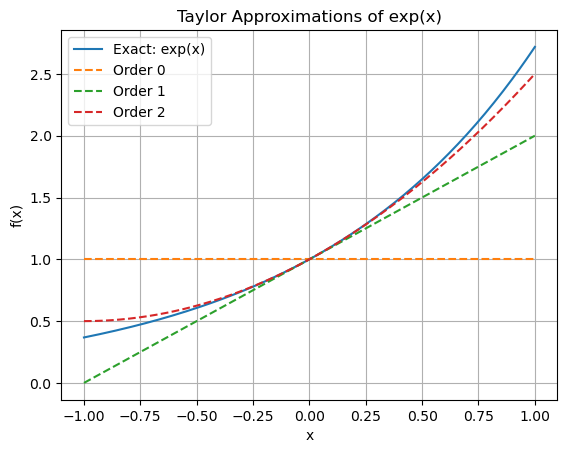

In [428]:
plt.plot(x, exact, label="Exact: exp(x)")
plt.plot(x, taylor_0, "--", label="Order 0")
plt.plot(x, taylor_1, "--", label="Order 1")
plt.plot(x, taylor_2, "--", label="Order 2")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Taylor Approximations of exp(x)")
plt.legend()
plt.grid()
plt.show()

### Interpretation

The second-order approximation follows the curvature of the exact function.

Near the expansion point, it is more accurate than the zeroth- and first-order approximations.

The improvement occurs because the second-order approximation matches

- the function value,
- the first derivative,
- the second derivative

at the expansion point.

## Question 4

Find the second-order Taylor approximation of

$$
f(x)=\cos(x)
$$

around

$$
x_0=0.
$$

## Solution 4

The second-order formula is

$$
f(x_0+h)
\approx
f(x_0)
+
h f'(x_0)
+
\frac{h^2}{2}f''(x_0).
$$

For

$$
f(x)=\cos(x),
$$

we have

$$
f(0)=1.
$$

The first derivative is

$$
f'(x)=-\sin(x),
$$

so

$$
f'(0)=0.
$$

The second derivative is

$$
f''(x)=-\cos(x),
$$

so

$$
f''(0)=-1.
$$

Substitution gives

$$
\cos(h)
\approx
1+h(0)+\frac{h^2}{2}(-1).
$$

Therefore,

$$
\cos(h)\approx 1-\frac{h^2}{2}.
$$

Since $x_0=0$,

$$
\cos(x)\approx 1-\frac{x^2}{2}.
$$

## 3.6 General Taylor Formula

The Taylor expansion of a sufficiently smooth function around $x_0$ is

$$
f(x_0+h)
=
f(x_0)
+
h f'(x_0)
+
\frac{h^2}{2!}f''(x_0)
+
\frac{h^3}{3!}f^{(3)}(x_0)
+
\cdots.
$$

Using summation notation,

$$
f(x_0+h)
=
\sum_{k=0}^{\infty}
\frac{h^k}{k!}
f^{(k)}(x_0).
$$

Here,

$$
f^{(k)}(x_0)
$$

means the $k$-th derivative of the function evaluated at $x_0$.

The first few cases are

$$
f^{(0)}(x_0)=f(x_0),
$$

$$
f^{(1)}(x_0)=f'(x_0),
$$

$$
f^{(2)}(x_0)=f''(x_0).
$$

### Maclaurin Series

A Taylor series expanded around

$$
x_0=0
$$

is called a **Maclaurin series**.

The general Maclaurin series is

$$
f(x)
=
f(0)
+
x f'(0)
+
\frac{x^2}{2!}f''(0)
+
\frac{x^3}{3!}f^{(3)}(0)
+
\cdots.
$$

The Taylor expansions of $e^x$, $\sin(x)$ and $\cos(x)$ around zero are Maclaurin series.

## Question 5

What is the difference between a Taylor series and a Maclaurin series?

## Solution 5

A Taylor series can be expanded around any point $x_0$.

A Maclaurin series is a special Taylor series whose expansion point is

$$
x_0=0.
$$

## 3.7 Important Taylor Expansions

We only need a few standard expansions in this course.

They help us understand approximation, error and numerical discretisation.

### Exponential Function

The derivatives of

$$
f(x)=e^x
$$

are always equal to $e^x$.

At $x_0=0$, every derivative has the value $1$.

Therefore,

$$
e^x
=
1
+
x
+
\frac{x^2}{2!}
+
\frac{x^3}{3!}
+
\frac{x^4}{4!}
+
\cdots.
$$

### Sine Function

The derivatives of $\sin(x)$ repeat in a cycle:

$$
\sin(x),
\qquad
\cos(x),
\qquad
-\sin(x),
\qquad
-\cos(x),
\qquad
\sin(x).
$$

At $x=0$,

$$
\sin(0)=0,
$$

$$
\cos(0)=1.
$$

Therefore,

$$
\sin(x)
=
x
-
\frac{x^3}{3!}
+
\frac{x^5}{5!}
-
\frac{x^7}{7!}
+
\cdots.
$$

Only odd powers appear because the even derivatives of $\sin(x)$ are zero at $x=0$.

### Cosine Function

The derivatives of $\cos(x)$ also repeat in a cycle.

At $x=0$, the odd derivatives are zero.

Therefore,

$$
\cos(x)
=
1
-
\frac{x^2}{2!}
+
\frac{x^4}{4!}
-
\frac{x^6}{6!}
+
\cdots.
$$

Only even powers appear.

## Question 6

Why does the Maclaurin series of $\sin(x)$ contain only odd powers of $x$?

## Solution 6

The coefficients of the Taylor series depend on derivatives evaluated at $x=0$.

For $\sin(x)$, the derivatives associated with even powers contain either $\sin(0)$ or $-\sin(0)$.

Since

$$
\sin(0)=0,
$$

all coefficients of the even powers are zero.

Therefore, only odd powers remain.

## 3.8 Comparing Taylor Orders Numerically

We now compare different Taylor approximations of

$$
\sin(x)
$$

around

$$
x_0=0.
$$

We use the following approximations:

First-order:

$$
T_1(x)=x.
$$

Third-order:

$$
T_3(x)=x-\frac{x^3}{3!}.
$$

Fifth-order:

$$
T_5(x)=x-\frac{x^3}{3!}+\frac{x^5}{5!}.
$$

In [429]:
x = np.linspace(-2.0, 2.0, 400)

exact_sin = np.sin(x)

taylor_sin_1 = x
taylor_sin_3 = x - x**3 / 6
taylor_sin_5 = x - x**3 / 6 + x**5 / 120

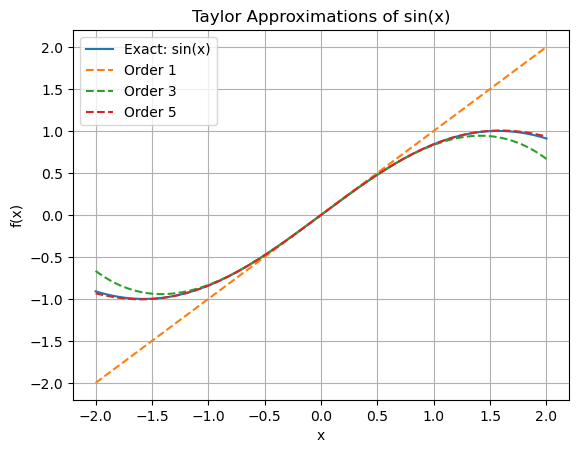

In [430]:
plt.plot(x, exact_sin, label="Exact: sin(x)")
plt.plot(x, taylor_sin_1, "--", label="Order 1")
plt.plot(x, taylor_sin_3, "--", label="Order 3")
plt.plot(x, taylor_sin_5, "--", label="Order 5")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Taylor Approximations of sin(x)")
plt.legend()
plt.grid()
plt.show()

### Interpretation

All approximations agree with the exact function near $x=0$.

The higher-order approximations remain accurate over a larger interval.

However, Taylor expansion is still a local approximation.

Even a higher-order approximation may become inaccurate sufficiently far from the expansion point.

## 3.9 Approximation Error

A numerical approximation is generally not exactly equal to the true value.

The error is the difference between the exact value and the approximate value.

We define the absolute error as

$$
E(x)
=
\left|
f(x)-T(x)
\right|,
$$

where

- $f(x)$ is the exact function,
- $T(x)$ is the Taylor approximation.

The absolute value is used because we usually care about the size of the error, not its sign.

In [431]:
error_1 = np.abs(exact_sin - taylor_sin_1)
error_3 = np.abs(exact_sin - taylor_sin_3)
error_5 = np.abs(exact_sin - taylor_sin_5)

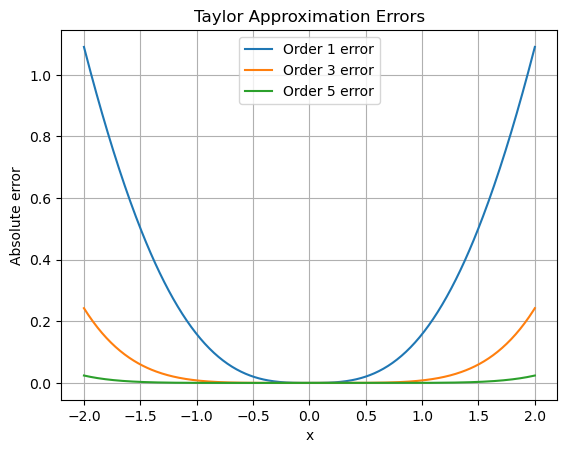

In [432]:
plt.plot(x, error_1, label="Order 1 error")
plt.plot(x, error_3, label="Order 3 error")
plt.plot(x, error_5, label="Order 5 error")

plt.xlabel("x")
plt.ylabel("Absolute error")
plt.title("Taylor Approximation Errors")
plt.legend()
plt.grid()
plt.show()

### Maximum Absolute Error

A single number can be used to summarise the largest error over the grid.

The maximum absolute error is

$$
E_{\max}
=
\max_j
\left|
f(x_j)-T(x_j)
\right|.
$$

The index $j$ represents the discrete grid points.

In [433]:
max_error_1 = np.max(error_1)
max_error_3 = np.max(error_3)
max_error_5 = np.max(error_5)

print("Maximum error, order 1:", max_error_1)
print("Maximum error, order 3:", max_error_3)
print("Maximum error, order 5:", max_error_5)

Maximum error, order 1: 1.0907025731743183
Maximum error, order 3: 0.24263076015901497
Maximum error, order 5: 0.02403590650765164


## Question 7

Which approximation should normally have the smallest error near the expansion point?

- first-order,

- third-order,

- fifth-order.

## Solution 7

The fifth-order approximation should normally have the smallest error near the expansion point.

It contains more terms from the Taylor series and therefore matches more derivatives of the exact function at $x_0$.

However, this conclusion is local. The quality of the approximation also depends on the distance from the expansion point.

## 3.10 Truncation Error

A complete Taylor series may contain infinitely many terms.

A computer cannot use infinitely many terms.

We therefore stop the series after a finite number of terms.

This process is called **truncation**.

The error caused by removing the remaining terms is called the **truncation error**.

For example,

$$
e^h
=
1+h+\frac{h^2}{2!}
+\frac{h^3}{3!}
+\cdots.
$$

If we keep only the first two terms,

$$
e^h\approx1+h,
$$

the neglected terms begin with

$$
\frac{h^2}{2!}.
$$

Therefore, the leading truncation error has size proportional to $h^2$.

### Leading Error Term

The first neglected non-zero term usually determines the order of the truncation error.

For

$$
e^h\approx1+h,
$$

the first neglected term is

$$
\frac{h^2}{2}.
$$

For

$$
e^h\approx1+h+\frac{h^2}{2},
$$

the first neglected term is

$$
\frac{h^3}{6}.
$$

This observation is central to numerical error analysis.

## Question 8

Consider the approximation

$$
\sin(h)\approx h.
$$

What is the first neglected non-zero term?

## Solution 8

The Taylor series of sine is

$$
\sin(h)
=
h
-
\frac{h^3}{3!}
+
\frac{h^5}{5!}
-
\cdots.
$$

The approximation keeps only the first term $h$.

Therefore, the first neglected non-zero term is

$$
-\frac{h^3}{3!}.
$$

Its magnitude is proportional to

$$
h^3.
$$

## 3.11 Big-O Notation

Big-O notation describes how an error behaves as a small parameter approaches zero.

If the leading error term is proportional to $h^p$, we write

$$
E(h)=\mathcal{O}(h^p).
$$

The number $p$ is called the **order**.

For example,

$$
E(h)=\mathcal{O}(h)
$$

means that the leading error behaves like $h$.

Similarly,

$$
E(h)=\mathcal{O}(h^2)
$$

means that the leading error behaves like $h^2$.

The order describes how quickly the error decreases when $h$ becomes smaller.

### Error Reduction Under Grid Refinement

Suppose

$$
E(h)=C h^p,
$$

where $C$ is approximately constant.

If the step size is divided by two,

$$
h_{\mathrm{new}}=\frac{h}{2},
$$

then

$$
E\left(\frac{h}{2}\right)
=
C\left(\frac{h}{2}\right)^p.
$$

Therefore,

$$
E\left(\frac{h}{2}\right)
=
\frac{1}{2^p}E(h).
$$

This gives the following important pattern:

| Order | Error after halving $h$ |
|---:|---:|
| $p=1$ | approximately divided by $2$ |
| $p=2$ | approximately divided by $4$ |
| $p=3$ | approximately divided by $8$ |
| $p=4$ | approximately divided by $16$ |

## Question 9

A numerical method has error

$$
E(h)=\mathcal{O}(h^2).
$$

Approximately what happens to the error when $h$ is divided by two?

## Solution 9

For a second-order method,

$$
E(h)\propto h^2.
$$

After dividing $h$ by two,

$$
E\left(\frac{h}{2}\right)
\approx
\frac{1}{2^2}E(h).
$$

Therefore,

$$
E\left(\frac{h}{2}\right)
\approx
\frac14 E(h).
$$

The error is approximately divided by four.

## 3.12 Numerical Verification of Order

We can test an expected order numerically.

Consider the first-order Taylor approximation

$$
e^h\approx1+h.
$$

The first neglected term is proportional to $h^2$.

Therefore, we expect

$$
\left|e^h-(1+h)\right|
=
\mathcal{O}(h^2).
$$

If we halve $h$, the error should be approximately divided by four.

In [434]:
step_sizes = np.array([0.4, 0.2, 0.1, 0.05, 0.025])

exact_values = np.exp(step_sizes)
approx_values = 1 + step_sizes

errors = np.abs(exact_values - approx_values)

for h, error in zip(step_sizes, errors):
    print(f"h = {h:.3f}, error = {error:.8f}")

h = 0.400, error = 0.09182470
h = 0.200, error = 0.02140276
h = 0.100, error = 0.00517092
h = 0.050, error = 0.00127110
h = 0.025, error = 0.00031512
